# 03 · Moving frames

Companion notebook for *Questioning the mathematical foundations of AI*, Dr Ana Rojo-Echeburúa, PyCon España 2026.

## What this notebook does

Notebooks 01 and 02 compared two geometries, flat and hyperbolic. This one asks the question underneath both of them: **what does it actually mean to choose a geometry?**

The answer goes back to Felix Klein in 1872. A geometry is defined by its symmetries, the transformations you've decided don't matter, and the things worth measuring are the things those transformations leave unchanged. Moving frames are the tool that turns this idea into an algorithm. You give it a group of symmetries, it puts every object into a standard position, and whatever is left over is an invariant.

This is my research area (my PhD was on moving frames and Noether's conservation laws), so I'll be a bit more precise here than in the other notebooks. Every step still starts with the idea before the formulas.

## The steps

1. **Klein's idea.** A geometry is what survives a group of transformations.
2. **What a moving frame is.** The definition, and a four-step recipe.
3. **SymPy: the curvature of a curve.** We run the recipe on a plane curve and curvature falls out.
4. **Noether in one cell.** Symmetries give conservation laws, and frames make them readable.
5. **A moving frame for the Poincaré disk.** The frame behind the talk's demo, and the invariant it hands you.
6. **The demo.** Where to find the full search demo (notebook 05).
7. **Why this matters for embeddings.** Arbitrary cosine, equivariant ML and conservation laws in training.
8. **Closing thought.**

## Setup

In [1]:
import logging
import warnings
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import torch

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

BG, TEXT = "#CFD5D3", "#030303"
BROWN, DARK_BROWN, SLATE, LIGHT_GREY = "#7F584A", "#4F3733", "#767F87", "#A9B0B4"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "figure.dpi": 110,
})
sp.init_printing()
print("sympy", sp.__version__, "| torch", torch.__version__)

sympy 1.14.0 | torch 2.15.0


**What you're seeing:** just the setup and versions. SymPy does the algebra in this notebook, so nothing here needs a GPU or a model download.

## Step 1 · Klein's idea

In 1872 Felix Klein, newly appointed at Erlangen, published what became known as the **Erlangen programme**. His idea was that a geometry is the study of the properties that stay the same under a **group** of transformations. Choose the group and you've chosen the geometry.

Here's that idea applied to the similarity measures from notebooks 01 and 02:

| Geometry | Transformations that "don't matter" (the group) | What survives (the invariants) |
|---|---|---|
| Euclidean | $E(n)$: move, rotate, reflect | distances and angles |
| Cosine | rotations about the origin, plus rescaling each vector by its own positive number | angles between vectors |
| Hyperbolic | $O^+(n, 1)$, the Lorentz transformations | hyperbolic distance |

Read the middle row carefully. Cosine similarity says the length of every vector is irrelevant, so you can stretch or shrink each one separately and nothing changes. That's a strong modelling decision, and most of us make it without noticing.

So here's the line I'd like you to remember from the talk: **your similarity metric is a statement about what you decided doesn't matter.**

## Step 2 · What a moving frame is

The idea goes back to Élie Cartan's *repère mobile* (moving frame), a coordinate system that rides along with the object you're studying. Fels & Olver (Acta Appl. Math., 1998 and 1999) turned it into a general algorithm that works for any Lie group action, and that's the version I use.

**The idea:** to compare two objects without being fooled by the transformations you don't care about, first move each one into a standard position. Whatever still differs once they're both in standard position is real.

**Precisely:** let a Lie group $G$ act on a space $M$, written $z \mapsto g \cdot z$, and suppose the action is free and regular (near the points we care about). A **right moving frame** is a map $\rho : M \to G$ that is equivariant,

$$\rho(g \cdot z) = \rho(z)\, g^{-1},$$

and the **invariants** are the components of $I(z) = \rho(z) \cdot z$. You can check the equivariance does the job: $I(g \cdot z) = \rho(z) g^{-1} \cdot (g \cdot z) = \rho(z) \cdot z = I(z)$, so $I$ doesn't see $g$ at all.

**The recipe:**

1. **Pick the group.** Which transformations don't matter?
2. **Choose normalisation equations.** Set some coordinates of $g \cdot z$ to constants (usually 0). These define a cross-section $K$, the "standard position".
3. **Solve for the frame.** Solve the normalisation equations for $g$. The solution is $\rho(z)$.
4. **Read off what's left.** Apply $\rho(z)$ to the remaining coordinates. Those are the invariants.

A useful count: if $G$ has dimension $r$ and acts freely on a space of dimension $m$, you get $m - r$ independent invariants. Every normalisation equation uses up one group parameter.

## Step 3 · SymPy: the curvature of a plane curve under SE(2)

Let's run the recipe on a classic. Take a curve in the plane written as a graph $u = u(x)$, and say that **rigid motions don't matter**: translations and rotations, the special Euclidean group $SE(2)$. It has 3 parameters (an angle $\theta$ and a translation $(a, b)$) and acts on points by

$$\tilde{x} = x\cos\theta - u\sin\theta + a, \qquad \tilde{u} = x\sin\theta + u\cos\theta + b .$$

A curve is more than its points, though, because it has a slope $u_x$, a second derivative $u_{xx}$ and so on. The group moves those too (this is called the **prolonged action**), and we get it with the chain rule, using the total derivative $D_x = \partial_x + u_x \partial_u + u_{xx} \partial_{u_x} + \dots$:

$$\tilde{u}_{\tilde{x}} = \frac{D_x \tilde{u}}{D_x \tilde{x}}, \qquad \tilde{u}_{\tilde{x}\tilde{x}} = \frac{D_x \tilde{u}_{\tilde{x}}}{D_x \tilde{x}} .$$

SymPy can do all of that for us.

In [2]:
x, u, u_x, u_xx = sp.symbols("x u u_x u_xx", real=True)
theta, a, b = sp.symbols("theta a b", real=True)

# 1. The group SE(2) acting on the point (x, u)
X = x * sp.cos(theta) - u * sp.sin(theta) + a
U = x * sp.sin(theta) + u * sp.cos(theta) + b

# Prolong the action to derivatives with the total derivative D_x
def D(f):
    return sp.diff(f, x) + u_x * sp.diff(f, u) + u_xx * sp.diff(f, u_x)

U_X = sp.simplify(D(U) / D(X))
U_XX = sp.simplify(D(U_X) / D(X))

print("transformed slope:            ", U_X)
print("transformed second derivative:", U_XX)

transformed slope:             (u_x*cos(theta) + sin(theta))/(-u_x*sin(theta) + cos(theta))
transformed second derivative: -u_xx/(u_x*sin(theta) - cos(theta))**3


**What you're seeing:** the chain rule did its job. The new slope is a fraction that mixes the old slope with the rotation angle, and the new second derivative is $u_{xx}$ divided by $(\cos\theta - u_x \sin\theta)^3$. The translation $(a, b)$ has dropped out of both, which makes sense, because sliding a curve around doesn't change its slope or how much it bends.

Now the recipe. $SE(2)$ has 3 parameters, so we need 3 normalisation equations. The natural ones are:

- $\tilde{x} = 0$ and $\tilde{u} = 0$: translate the point on the curve to the origin.
- $\tilde{u}_{\tilde{x}} = 0$: rotate so the tangent line is flat.

The slope equation only involves $\theta$, so we solve it first, taking the branch with $\cos\theta > 0$ (so the curve still runs left to right). Then the other two give the translation.

check the slope normalisation: 0
translation part of the frame: {a: -u*u_x/sqrt(u_x**2 + 1) - x/sqrt(u_x**2 + 1), b: -u/sqrt(u_x**2 + 1) + u_x*x/sqrt(u_x**2 + 1)}

what survives at second order:


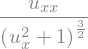

In [3]:
# 2 + 3. Normalise and solve for the frame
theta_frame = -sp.atan(u_x)                                      # from  sin(theta) + u_x cos(theta) = 0
print("check the slope normalisation:", sp.simplify(U_X.subs(theta, theta_frame)))

ab_frame = sp.solve([X.subs(theta, theta_frame), U.subs(theta, theta_frame)], [a, b])
print("translation part of the frame:", ab_frame)

# 4. Read off what's left: apply the frame to the second derivative
kappa = sp.simplify(U_XX.subs(theta, theta_frame))
print("\nwhat survives at second order:")
kappa

**What you're seeing:** solving the three normalisation equations gives the frame, a rotation by $\theta = -\arctan u_x$ plus a translation $(a, b)$ that depends on $x$, $u$ and $u_x$. Apply that frame to $u_{xx}$ and out comes $u_{xx}/(1 + u_x^2)^{3/2}$, the **curvature** $\kappa$. We never typed the curvature formula in. It's simply what's left once the frame has used up the group. The count from Step 2 agrees: the coordinates $(x, u, u_x, u_{xx})$ give a 4-dimensional space, the group has dimension 3, so there's exactly one invariant at second order.

Two checks. First, invariance: if we transform the curve by **any** element of $SE(2)$ and compute $\kappa$ again, we should get the same answer. Second, a circle of radius $R$ should have curvature $1/R$.

kappa after any rigid motion  minus  kappa before:


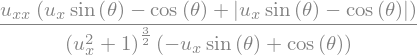

largest difference over 1,000 rigid motions that keep the curve running left to right: 0.0e+00
(skipped 984 random motions that turn the curve round, where kappa changes sign)

curvature of a circle of radius R: -1/R


In [4]:
def curvature(slope, second):
    return second / (1 + slope ** 2) ** sp.Rational(3, 2)

difference = sp.simplify(curvature(U_X, U_XX) - curvature(u_x, u_xx))
print("kappa after any rigid motion  minus  kappa before:")
display(difference)

# Numerical spot check: random rigid motions and random jets
rng = np.random.default_rng(SEED)
worst, flipped, checked = 0.0, 0, 0
while checked < 1000:
    vals = {theta: rng.uniform(-np.pi, np.pi), u_x: rng.normal(), u_xx: rng.normal(), x: rng.normal(), u: rng.normal(), a: rng.normal(), b: rng.normal()}
    if float(D(X).subs(vals)) <= 0:      # this motion turns the curve round to run right to left
        flipped += 1
        continue
    worst = max(worst, abs(float(difference.subs(vals))))
    checked += 1
print(f"largest difference over {checked:,} rigid motions that keep the curve running left to right: {worst:.1e}")
print(f"(skipped {flipped:,} random motions that turn the curve round, where kappa changes sign)")

# A circle of radius R (upper half)
R = sp.symbols("R", positive=True)
circle = sp.sqrt(R ** 2 - x ** 2)
k_circle = sp.simplify(sp.powsimp(curvature(sp.diff(circle, x), sp.diff(circle, x, 2)), force=True))
print("\ncurvature of a circle of radius R:", k_circle)

**What you're seeing:** the symbolic difference isn't a plain 0, and it's worth reading. It contains $s + |s|$ with $s = u_x\sin\theta - \cos\theta = -D_x\tilde{x}$. Whenever $D_x\tilde{x} > 0$, meaning the rigid motion keeps the curve running left to right, that factor is exactly 0 and $\kappa$ is invariant. Rotate so far that the curve runs right to left and $\kappa$ flips sign, because signed curvature depends on the direction you travel along the curve, while $|\kappa|$ never changes. The 1,000 random motions that keep the direction give a difference of exactly 0. The circle comes out as $-1/R$, which is size $1/R$ as promised, and negative because the upper half of a circle bends downwards.

Here's the whole recipe as a picture, for the curve $u = \sin x$ at $x = 1$. The frame translates the point to the origin and rotates the tangent flat. In that standard position the curve looks like $u \approx \tfrac{1}{2}\kappa x^2$ near the origin, so the only thing left to read off is $\kappa$.

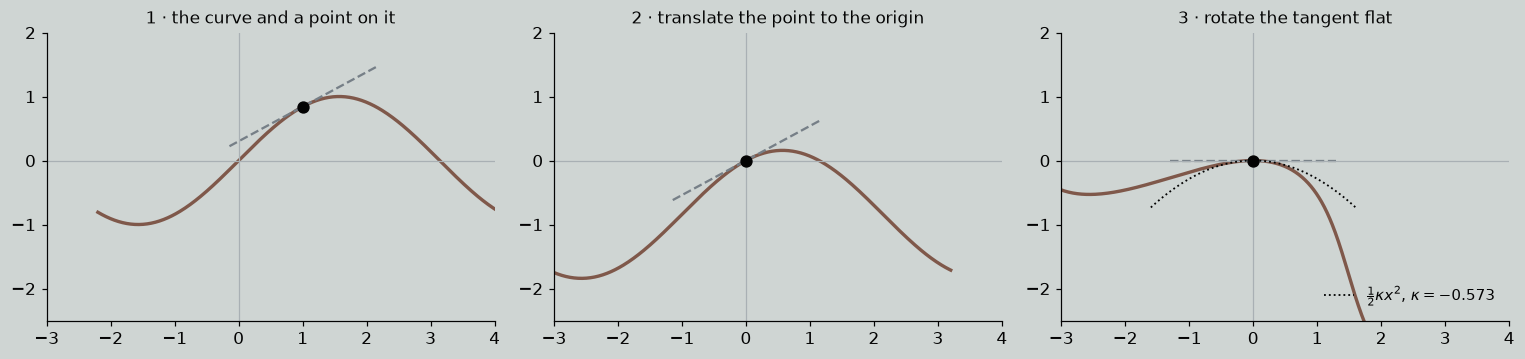

frame at x = 1:  theta = -0.4954, a = -1.2798, b = -0.2650
curvature there: -0.5730   (directly: -sin(1)/(1+cos(1)^2)^1.5 = -0.5730)


In [5]:
f = sp.sin(x)
x0 = 1.0
jets = {x: x0, u: float(f.subs(x, x0)), u_x: float(sp.diff(f, x).subs(x, x0)), u_xx: float(sp.diff(f, x, 2).subs(x, x0))}
th = float(theta_frame.subs(jets))
A, B = float(ab_frame[a].subs(jets)), float(ab_frame[b].subs(jets))
k0 = float(kappa.subs(jets))

xs = np.linspace(-2.2, 4.2, 400); us = np.sin(xs)
P = np.array([x0, np.sin(x0)]); T = np.array([1, np.cos(x0)]) / np.hypot(1, np.cos(x0))

def rigid(xx, uu, t, aa=0.0, bb=0.0):
    return xx * np.cos(t) - uu * np.sin(t) + aa, xx * np.sin(t) + uu * np.cos(t) + bb

panels = [
    ("1 · the curve and a point on it", (xs, us), P, T),
    ("2 · translate the point to the origin", (xs - P[0], us - P[1]), np.zeros(2), T),
    ("3 · rotate the tangent flat", rigid(xs, us, th, A, B), np.zeros(2), np.array([1.0, 0.0])),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (title, (cx, cu), p, t) in zip(axes, panels):
    ax.plot(cx, cu, color=BROWN, lw=2.2)
    ax.plot(*np.array([p - 1.3 * t, p + 1.3 * t]).T, color=SLATE, lw=1.5, ls="--")
    ax.scatter(*p, color=TEXT, s=50, zorder=3)
    ax.axhline(0, color=LIGHT_GREY, lw=0.8); ax.axvline(0, color=LIGHT_GREY, lw=0.8)
    ax.set_xlim(-3, 4); ax.set_ylim(-2.5, 2); ax.set_aspect("equal"); ax.set_title(title, fontsize=11)
xx = np.linspace(-1.6, 1.6, 100)
axes[2].plot(xx, 0.5 * k0 * xx ** 2, color=TEXT, lw=1.2, ls=":", label=rf"$\frac{{1}}{{2}}\kappa x^2$, $\kappa = {k0:.3f}$")
axes[2].legend(frameon=False, loc="lower right", fontsize=10)
plt.tight_layout(); plt.show()

print(f"frame at x = 1:  theta = {th:.4f}, a = {A:.4f}, b = {B:.4f}")
print(f"curvature there: {k0:.4f}   (directly: -sin(1)/(1+cos(1)^2)^1.5 = {-np.sin(1)/(1+np.cos(1)**2)**1.5:.4f})")

**What you're seeing:** the three steps of the recipe on a real curve. In panel 2 the point has moved to the origin and the tangent (dashed) still has the same slope. In panel 3 the tangent is flat, and near the origin the curve hugs the dotted parabola $\tfrac{1}{2}\kappa x^2$ with $\kappa = -0.573$, matching the formula evaluated directly. In standard position, a curve's whole second-order shape is one number.

## Step 4 · Noether in one cell

Emmy Noether's 1918 theorem connects symmetry to conservation. **Every continuous symmetry of a Lagrangian gives a conserved quantity.**

| Symmetry of the Lagrangian | Conserved quantity |
|---|---|
| shifting time | energy |
| shifting space | momentum |
| rotating space | angular momentum |

Here's the rotation row checked symbolically. A particle in the plane with a potential that only depends on the distance from the origin, $L = \tfrac{1}{2}(\dot{x}^2 + \dot{y}^2) - V(r)$, is unchanged by rotations, so the angular momentum $x\dot{y} - y\dot{x}$ should be constant along every solution of the equations of motion. SymPy confirms its time derivative is zero for *any* potential $V$.

In [6]:
t = sp.symbols("t")
xt, yt = sp.Function("x")(t), sp.Function("y")(t)
V = sp.Function("V")
L = (xt.diff(t) ** 2 + yt.diff(t) ** 2) / 2 - V(sp.sqrt(xt ** 2 + yt ** 2))

euler_lagrange = [sp.diff(L.diff(q.diff(t)), t) - L.diff(q) for q in (xt, yt)]
motion = sp.solve(euler_lagrange, [xt.diff(t, 2), yt.diff(t, 2)])

angular_momentum = xt * yt.diff(t) - yt * xt.diff(t)
print("d/dt (x y' - y x') along the motion =", sp.simplify(angular_momentum.diff(t).subs(motion)))

d/dt (x y' - y x') along the motion = 0


**What you're seeing:** the time derivative of the angular momentum is zero along every solution of the equations of motion, and SymPy never needed to know what $V$ is. All it used was that $L$ doesn't change when you rotate the plane. That's Noether's theorem in its simplest form.

Moving frames make these laws readable. Gonçalves & Mansfield (Stud. Appl. Math. 128, 2012) showed that for a Lagrangian invariant under a group $G$, Noether's conservation laws can always be written in the form

$$\mathrm{Ad}(\rho)^{-1}\, \upsilon(I) = c,$$

where $\rho$ is the moving frame, $\upsilon(I)$ is a vector built only from invariants, $\mathrm{Ad}$ is the adjoint representation of $G$, and $c$ is a vector of constants. The invariants carry the physics, and the frame carries the geometry. For Euler's elastica, the curve that minimises $\int \kappa^2 \, ds$ under $SE(2)$ (think of a thin bent ruler), the invariant part is

$$\upsilon(I) = (-\kappa^2,\; -2\kappa_s,\; 2\kappa),$$

with $\kappa$ the curvature we just derived and $\kappa_s$ its derivative along the curve.

The discrete version is what my own work is about. With difference moving frames you get Noether's conservation laws for **finite difference** schemes, the setting of numerical methods and of anything that runs on a computer step by step: Mansfield, Rojo-Echeburúa, Hydon & Peng (Trans. Math. Appl., 2019), and Mansfield & Rojo-Echeburúa (Trans. Math. Appl., 2019), worked through for $SL(2)$ acting linearly and projectively, and for the equi-affine action. For a full introduction to the continuous theory, Mansfield's *A Practical Guide to the Invariant Calculus* (Cambridge University Press, 2010) is the book I'd start with.

## Step 5 · A moving frame for the Poincaré disk

Now let's build the frame that sits behind the talk's demo. Write points of the Poincaré disk (notebook 02) as complex numbers $z$ with $|z| < 1$.

**1. The group.** The orientation-preserving isometries of the disk, the transformations that keep every hyperbolic distance the same, are

$$g_{\theta, a}(z) = e^{i\theta}\, \frac{z - a}{1 - \bar{a} z}, \qquad |a| < 1,\ \theta \in \mathbb{R}.$$

That's a 3-dimensional group (two real numbers in $a$, one in $\theta$), isomorphic to $PSU(1,1) \cong PSL(2, \mathbb{R})$.

**The space.** We want to compare two points, a query $a$ and a candidate $b$, so the group acts on **pairs** $(a, b) \in D \times D$, a space of real dimension 4. By the count from Step 2 we expect $4 - 3 = 1$ invariant.

**2. Normalisation equations.**
- Send the query to the centre, $g(a) = 0$. This fixes the Möbius part: $\rho(z) = (z - a)/(1 - \bar{a}z)$.
- Rotate so the image of $b$ lies on the positive real axis. This fixes $\theta$.

**3 + 4. What's left** is a single number, $r = |\rho(b)|$, the distance of $b$ from the centre once $a$ has been moved there. Because hyperbolic distance from the centre is $2\operatorname{artanh} r$, the invariant we report is $2 \operatorname{artanh} r$.

Here's the frame with two example points.

In [7]:
def frame(a):              # the isometry that sends a to the centre
    return lambda z: (z - a) / (1 - np.conj(a) * z)

def invariant(a, b):       # normalise, then read off what is left
    r = abs(frame(a)(b))   # rotating onto the axis leaves only |w|
    return 2 * np.arctanh(r)

def poincare_distance(a, b):
    return np.arccosh(1 + 2 * abs(a - b) ** 2 / ((1 - abs(a) ** 2) * (1 - abs(b) ** 2)))

a, b = 0.45 + 0.35j, -0.35 + 0.55j
w = frame(a)(b)
w_rot = np.exp(-1j * np.angle(w)) * w

print(f"frame(a)(a)     = {frame(a)(a)}")
print(f"after rotation  = {w_rot:.6f}   (real and positive)")
print(f"invariant       = {invariant(a, b):.15f}")
print(f"Poincaré formula = {poincare_distance(a, b):.15f}")

frame(a)(a)     = 0j
after rotation  = 0.797891+0.000000j   (real and positive)
invariant       = 2.185560917107912
Poincaré formula = 2.185560917107912


**What you're seeing:** the frame sends $a$ to exactly 0, and after the rotation $b$ sits at 0.797891 on the positive real axis. The invariant, $2\operatorname{artanh}(0.797891)$, agrees with the Poincaré distance formula from notebook 02 to all 15 printed digits. Again, we never typed the distance formula into `invariant`. The frame handed it to us as the only thing the symmetry leaves behind.

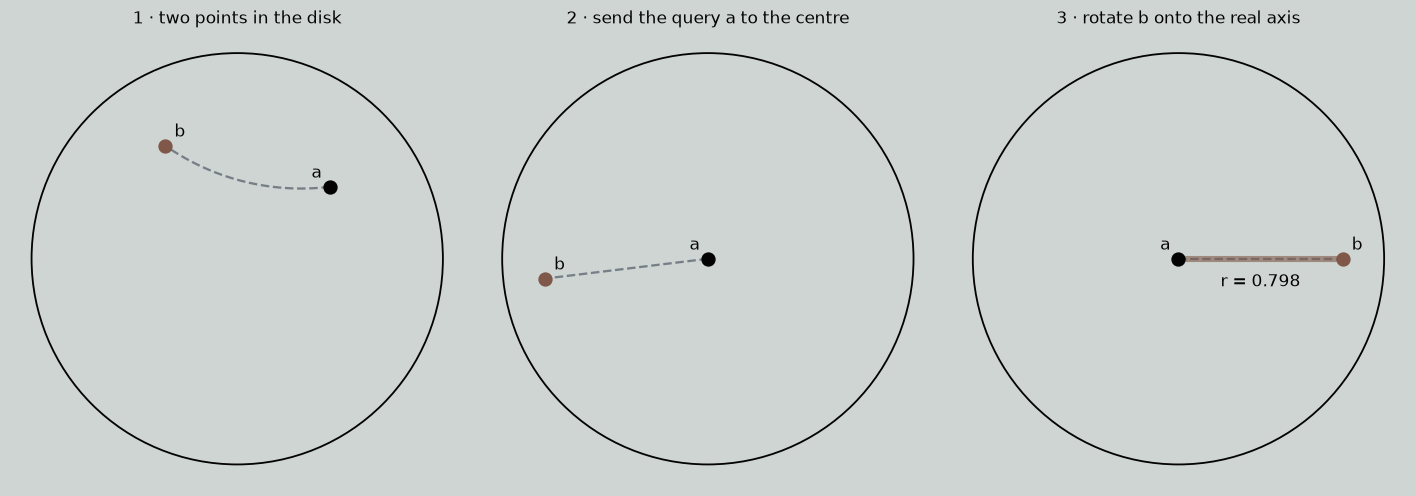

In [8]:
def disk(ax, title):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=TEXT, lw=1.2))
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=11)

def geodesic(p, q, n=80):  # slide p to the centre, draw a straight segment, slide back
    to0, back = frame(p), (lambda z: (z + p) / (1 + np.conj(p) * z))
    return back(np.linspace(0, 1, n) * to0(q))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
steps = [("1 · two points in the disk", a, b),
         ("2 · send the query a to the centre", 0j, w),
         ("3 · rotate b onto the real axis", 0j, w_rot)]
for ax, (title, p, q) in zip(axes, steps):
    disk(ax, title)
    g = geodesic(p, q); ax.plot(g.real, g.imag, color=SLATE, lw=1.5, ls="--")
    ax.scatter(p.real, p.imag, color=TEXT, s=70, zorder=3); ax.annotate("a", (p.real, p.imag), xytext=(-12, 6), textcoords="offset points")
    ax.scatter(q.real, q.imag, color=BROWN, s=70, zorder=3); ax.annotate("b", (q.real, q.imag), xytext=(6, 6), textcoords="offset points")
axes[2].plot([0, w_rot.real], [0, 0], color=BROWN, lw=4, alpha=0.6, zorder=2)
axes[2].annotate(f"r = {abs(w):.3f}", (w_rot.real / 2, 0), xytext=(0, -18), textcoords="offset points", ha="center")
plt.tight_layout(); plt.show()

**What you're seeing:** the dashed curve is the geodesic between the two points. In panel 1 it's a circular arc. In panel 2, with $a$ at the centre, it becomes a straight line, because geodesics through the centre are straight. In panel 3 it lies along the real axis, and the highlighted segment of Euclidean length $r = 0.798$ is the only information left. Every other number about the pair (where they were, which way they pointed) has been used up by the frame.

And here is the property that makes it a moving frame. Move **both** points by any isometry and the invariant doesn't budge.

In [9]:
rng = np.random.default_rng(SEED)
worst = 0.0
for _ in range(1000):
    c = 0.9 * np.sqrt(rng.uniform()) * np.exp(2j * np.pi * rng.uniform())   # random |c| < 0.9
    phi = rng.uniform(0, 2 * np.pi)
    g = lambda z: np.exp(1j * phi) * (z - c) / (1 - np.conj(c) * z)
    worst = max(worst, abs(invariant(g(a), g(b)) - invariant(a, b)))
print(f"largest change in the invariant over 1,000 random isometries: {worst:.1e}")

largest change in the invariant over 1,000 random isometries: 9.3e-15


**What you're seeing:** a change of about $10^{-14}$ over 1,000 random isometries, which is floating-point noise. Wherever you put the two points and however you rotate the disk, the frame finds the same standard position and reports the same number.

## Step 6 · The demo

The full demo from the talk lives in **[notebook 05](05_demo_moving_frame_search.ipynb)**, so the code is in one place. It uses exactly the `frame` and `invariant` functions above, on the 12-word hierarchy that gensim trained in notebook 02, and it:

- runs a nearest-neighbour search where the score is the frame's invariant,
- checks that the invariant matches the Poincaré distance formula and gensim's own distance to about 15 digits,
- moves the whole embedding by 100 random isometries and checks the search results never change,
- and shows that cosine similarity on the same vectors **does** change under those isometries.

## Step 7 · Why this matters for embeddings

**Arbitrary cosine is a symmetry problem.** Steck, Ekanadham & Kallus (WWW '24 Companion) showed that the cosine between learned embeddings can be arbitrary, because training is blind to a rescaling that cosine is sensitive to (notebook 01, Step 9). In the language of this notebook, the training loss is invariant under a group that the similarity measure isn't invariant under. A moving frame fixes that mismatch before you compare anything: decide which group doesn't matter, put everything in standard position for that group, and only then measure.

**Equivariant ML already uses frames.** Frame averaging (Puny et al., ICLR 2022) makes any network invariant or equivariant by averaging over a small set of frames. Learned canonicalisation (Kaba et al., ICML 2023) trains a network to output the frame, so the main network only ever sees objects in standard position. Moving Frame Net (Sangalli et al., NeurReps 2022) builds $SE(3)$-equivariant networks for 3D volumes from moving frames directly.

**Training has conservation laws too.** Kunin et al. (ICLR 2021) applied Noether's idea to the training of neural networks themselves. In a ReLU network you can multiply a neuron's incoming weights by any $\alpha > 0$ and divide its outgoing weights by $\alpha$, and the network computes exactly the same function, so the loss can't tell the difference. That's a continuous symmetry, and under gradient flow it gives a conserved quantity:

$$\lVert w_{\text{in}} \rVert^2 - \lVert w_{\text{out}} \rVert^2 = \text{constant}.$$

Let's watch it happen. Plain gradient descent with a small learning rate (so we're close to gradient flow), no weight decay and no momentum, which would both break the symmetry.

loss: 0.500 -> 0.406
largest change in any neuron's ||w_in||^2:              0.1545
largest change in any neuron's ||w_out||^2:             0.1545
largest change in any neuron's ||w_in||^2 - ||w_out||^2: 1.5e-05


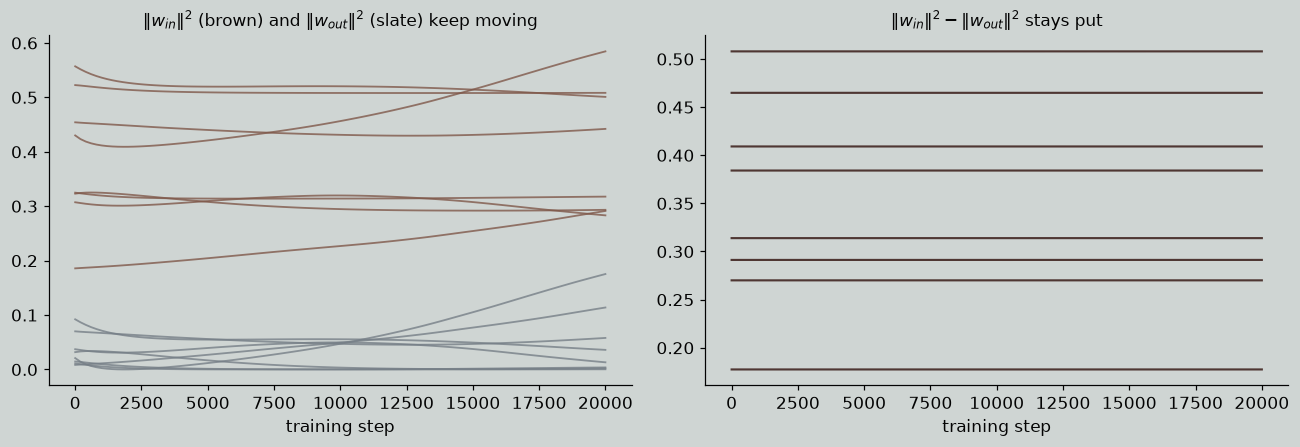

In [10]:
torch.manual_seed(SEED)
X_data = torch.randn(256, 5)
y_data = torch.sin(X_data.sum(dim=1, keepdim=True))

net = torch.nn.Sequential(torch.nn.Linear(5, 8), torch.nn.ReLU(), torch.nn.Linear(8, 1))
opt = torch.optim.SGD(net.parameters(), lr=1e-3, momentum=0, weight_decay=0)

def per_neuron():
    W1, b1, W2 = net[0].weight, net[0].bias, net[2].weight
    w_in = (W1 ** 2).sum(dim=1) + b1 ** 2          # incoming weights and bias of each hidden neuron
    w_out = (W2 ** 2).sum(dim=0)                   # outgoing weights of each hidden neuron
    return w_in.detach().clone(), w_out.detach().clone()

history_in, history_out, losses = [], [], []
for step in range(20001):
    if step % 200 == 0:
        i, o = per_neuron(); history_in.append(i); history_out.append(o)
    opt.zero_grad()
    loss = ((net(X_data) - y_data) ** 2).mean()
    loss.backward(); opt.step()
    losses.append(loss.item())

H_in, H_out = torch.stack(history_in).numpy(), torch.stack(history_out).numpy()
C = H_in - H_out
print(f"loss: {losses[0]:.3f} -> {losses[-1]:.3f}")
print(f"largest change in any neuron's ||w_in||^2:              {np.abs(H_in - H_in[0]).max():.4f}")
print(f"largest change in any neuron's ||w_out||^2:             {np.abs(H_out - H_out[0]).max():.4f}")
print(f"largest change in any neuron's ||w_in||^2 - ||w_out||^2: {np.abs(C - C[0]).max():.1e}")

steps = np.arange(len(C)) * 200
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for j in range(C.shape[1]):
    axes[0].plot(steps, H_in[:, j], color=BROWN, lw=1.2, alpha=0.8)
    axes[0].plot(steps, H_out[:, j], color=SLATE, lw=1.2, alpha=0.8)
    axes[1].plot(steps, C[:, j], color=DARK_BROWN, lw=1.4)
axes[0].set_title(r"$\|w_{in}\|^2$ (brown) and $\|w_{out}\|^2$ (slate) keep moving", fontsize=11)
axes[1].set_title(r"$\|w_{in}\|^2 - \|w_{out}\|^2$ stays put", fontsize=11)
for ax in axes: ax.set_xlabel("training step")
plt.tight_layout(); plt.show()

**What you're seeing:** the loss goes down (0.500 to 0.406), and the individual squared norms move by up to 0.15 as the network trains. Yet for every hidden neuron the difference $\lVert w_{\text{in}} \rVert^2 - \lVert w_{\text{out}} \rVert^2$ is a flat line, changing by at most $1.5 \times 10^{-5}$. It isn't exactly constant because gradient descent takes finite steps and only approximates gradient flow, so the drift shrinks as the learning rate does. A symmetry nobody designed into the network, the ReLU rescaling, quietly fixes eight numbers for the whole of training.

## Step 8 · Closing thought

Decide which symmetries matter, build the geometry around them, then measure only what survives.

Everything in this repo is that sentence applied to a different group. Cosine picked rotations and rescaling without asking, hyperbolic space picks the Lorentz group because hierarchies need room, and moving frames are how you get from "this group doesn't matter" to "this is the number to compare". Head to [notebook 04](04_curved_spaces_in_python.ipynb) to try curved spaces in Python yourself, or straight to [notebook 05](05_demo_moving_frame_search.ipynb) for the demo.